# UPI Technical Declines — Interim Report Analysis
**QM 640 Data Analytics Capstone · Karthikeyan S · Walsh College**

*Technical Declines in India's Unified Payments Interface: Effects of Volume Shifts and Regulatory Interventions*

This notebook reproduces every number, table and figure in the interim report from the public repository
(`karthick2613-git/ms_upi_capstone`). Run **Runtime → Run all**. Figures are also saved to `outputs/`.

| Notebook section | Report section |
|---|---|
| 1. Setup and data | Data Description |
| 2. Cleaning log | Analysis → Data Cleaning (Table 4) |
| 3. Sample size | Data Description → Sample Size and Power (Table 3) |
| 4. EDA | Analysis → EDA (Tables 5–6, Figures 4–9) |
| 5. RQ1, RQ3, RQ4 | Preliminary Results (Tables 10, Figure 11) |
| 6. RQ2 | Preliminary Results (Table 11, Figure 10) |
| 7. Prediction benchmark | Preliminary Model Performance (Tables 12–13, Figure 12) |

## 1. Setup and data

In [1]:
# Clone the public repo (skip if already cloned) and move into it
import os, subprocess
REPO = "https://github.com/karthick2613-git/ms_upi_capstone.git"
if not os.path.exists("data/processed/upi_remitter_top50_panel.csv"):
    if not os.path.exists("ms_upi_capstone"):
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir("ms_upi_capstone")
os.makedirs("outputs", exist_ok=True)
print("Working in:", os.getcwd())
print(sorted(os.listdir("data/processed")))

Working in: /home/claude/nbtest
['file_log.csv', 'month_audit.csv', 'upi_remitter_top50_panel.csv']


In [2]:
%matplotlib inline
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.duration.hazard_regression import PHReg
from scipy import stats
import xgboost as xgb
from sklearn.metrics import average_precision_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
OUT = "outputs/"
res = {}

plt.rcParams.update({"font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#555555", "axes.labelcolor": "#222222", "xtick.color": "#333333",
                     "ytick.color": "#333333", "axes.grid": True, "grid.color": "#e3e3e3", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 100, "savefig.dpi": 200})
BLUE, ORANGE, GREY, DARK = "#1f5a8a", "#c8641a", "#8a8a8a", "#222222"

In [3]:
# ------------------------------------------------------------------ load
raw = pd.read_csv("data/processed/upi_remitter_top50_panel.csv")
months = sorted(raw.month.unique()); midx = {m: i for i, m in enumerate(months)}
raw["t"] = raw.month.map(midx)
res["panel"] = dict(rows=len(raw), cols=raw.shape[1], months=len(months), first=months[0], last=months[-1],
                    raw_names=int(raw.bank_raw.nunique()), banks=int(raw.bank.nunique()), entities=int(raw.entity.nunique()),
                    nonbank_rows=int((~raw.is_bank).sum()), bank_rows=int(raw.is_bank.sum()))

raw.head()

,month,file_month,rank,bank_raw,bank,volume_mn,approved_pct,bd_pct,td_pct,debit_reversal_mn,debit_reversal_success_pct,source_file,month_source,n_member_rows,entity,is_bank,pct_sum,t
0,2024-01,2024-01,1,State Bank Of India,State Bank of India,3128.97,95.62,4.19,0.19,11.58,96.85,b637e410-Ecosystem-Statistics-UPI-Top-50-membe...,sheet title,1,State Bank of India,True,100.0,0
1,2024-01,2024-01,2,HDFC BANK LTD,HDFC Bank,1040.25,96.49,3.51,0.00,3.34,98.84,b637e410-Ecosystem-Statistics-UPI-Top-50-membe...,sheet title,1,HDFC Bank,True,100.0,0
2,2024-01,2024-01,3,Bank of Baroda,Bank of Baroda,781.72,95.28,4.68,0.04,2.71,98.54,b637e410-Ecosystem-Statistics-UPI-Top-50-membe...,sheet title,1,Bank of Baroda,True,100.0,0
3,2024-01,2024-01,4,Union Bank of India,Union Bank of India,753.66,94.51,4.34,1.15,7.16,46.76,b637e410-Ecosystem-Statistics-UPI-Top-50-membe...,sheet title,1,Union Bank of India,True,100.0,0
4,2024-01,2024-01,5,Punjab National Bank,Punjab National Bank,618.95,94.78,4.95,0.27,2.61,88.58,b637e410-Ecosystem-Statistics-UPI-Top-50-membe...,sheet title,1,Punjab National Bank,True,100.0,0


## 2. Cleaning log (Table 4)
Counts behind each cleaning decision: missing values, zero TD, duplicates, percentage identity, outliers and spike flags.
Real observations are kept; judgment calls are flagged.

In [4]:
# ------------------------------------------------------------------ cleaning log numbers
n = len(raw)
res["cleaning"] = dict(
    n_rows=n,
    missing_debit_rev=int(raw.debit_reversal_mn.isna().sum()), missing_debit_succ=int(raw.debit_reversal_success_pct.isna().sum()),
    missing_core=int(raw[["volume_mn", "approved_pct", "bd_pct", "td_pct"]].isna().sum().sum()),
    zero_td=int((raw.td_pct == 0).sum()),
    dup_month_bank=int(raw.duplicated(["month", "bank"]).sum()),
    two_member_rows=int((raw.n_member_rows > 1).sum()),
    pct_sum_max_dev=float((raw.pct_sum - 100).abs().max()),
    title_mismatch_rows=int((raw.month_source != "sheet title").sum()),
    n_months_49=int((raw.groupby("month").size() == 49).sum()),
)
d = raw[raw.is_bank].copy().sort_values(["entity", "t"]).reset_index(drop=True)
d["p"] = (d.td_pct / 100).clip(lower=0.000025)
d["logit"] = np.log(d.p / (1 - d.p)); d["lnV"] = np.log(d.volume_mn)
d["dlnV"] = d.groupby("entity").lnV.diff()
d["gap"] = d.groupby("entity").t.diff()
d.loc[d.gap != 1, "dlnV"] = np.nan
d["cummax_prev"] = d.groupby("entity").lnV.transform(lambda x: x.cummax().shift(1))
d["newpeak"] = ((d.lnV > d.cummax_prev) & d.cummax_prev.notna()).astype(int)
d["mon"] = d.month.str[5:].astype(int)
d["peak"] = d.mon.isin([3, 10, 11]).astype(int)
d["post"] = (d.month >= "2025-08").astype(int)

# outlier flags
med = d.groupby("entity").td_pct.transform("median")
mad = d.groupby("entity").td_pct.transform(lambda x: (x - x.median()).abs().median()) * 1.4826
d["rz"] = (d.td_pct - med) / mad.replace(0, np.nan)
d["spike"] = ((d.rz > 3) & (d.td_pct >= 1.0)).astype(int)
q1, q3 = d.td_pct.quantile([.25, .75]); iqr = q3 - q1
res["cleaning"].update(dict(iqr_upper=float(q3 + 1.5 * iqr), iqr_outliers=int((d.td_pct > q3 + 1.5 * iqr).sum()),
                            n_bank=len(d), spike_months=int(d.spike.sum()), spike_banks=int(d[d.spike == 1].entity.nunique()),
                            td_max=float(d.td_pct.max()), td_p99=float(d.td_pct.quantile(.99)),
                            vol_max_share=float(d.volume_mn.max() / d.groupby("month").volume_mn.sum().iloc[0])))
res["cleaning"]["td_max_row"] = d.loc[d.td_pct.idxmax(), ["entity", "month", "td_pct", "volume_mn"]].to_dict()
print(pd.Series(res['cleaning']).to_string())

n_rows                                                              1598
missing_debit_rev                                                     29
missing_debit_succ                                                     3
missing_core                                                           0
zero_td                                                               70
dup_month_bank                                                         0
two_member_rows                                                        2
pct_sum_max_dev                                                     0.01
title_mismatch_rows                                                   50
n_months_49                                                            2
iqr_upper                                                         2.1825
iqr_outliers                                                         166
n_bank                                                              1555
spike_months                                       

In [5]:
# bank groups (rule-based, documented)
PUBLIC = ["State Bank of India", "Bank of Baroda", "Punjab National Bank", "Canara Bank", "Union Bank of India", "Bank of India",
          "Indian Bank", "Indian Overseas Bank", "Central Bank of India", "UCO Bank", "Bank of Maharashtra", "Punjab & Sind Bank"]
PRIVATE = ["HDFC Bank", "ICICI Bank", "Axis Bank", "Kotak Mahindra Bank", "IndusInd Bank", "YES Bank", "IDFC FIRST Bank",
           "Federal Bank", "RBL Bank", "Bandhan Bank", "South Indian Bank", "Karur Vysya Bank", "City Union Bank",
           "Karnataka Bank", "Jammu & Kashmir Bank", "Tamilnad Mercantile Bank", "IDBI Bank"]
def grp(e):
    if e in PUBLIC: return "Public sector"
    if e in PRIVATE: return "Private sector"
    if "Small Finance" in e: return "Small finance"
    if "Payments Bank" in e: return "Payments bank"
    if "Gramin" in e or "Grameena" in e: return "Regional rural"
    return "Other"
d["group"] = d.entity.map(grp)
res["groups"] = d.groupby("group").entity.nunique().to_dict()
res['groups']

{'Other': 4,
 'Payments bank': 6,
 'Private sector': 17,
 'Public sector': 12,
 'Regional rural': 11,
 'Small finance': 6}

## 3. Sample size and power (Table 3)
Runs the repository's `code/sample_size.py` (power for slope, CI width, Fisher z, events per variable).

In [6]:
r = subprocess.run(["python", "sample_size.py"], cwd="code", capture_output=True, text=True)
print(r.stdout[-3500:] or r.stderr[-2000:])

{
 "z_alpha": 1.959963984540054,
 "z_beta": 0.8416212335729143,
 "K": 2.8015852181129683,
 "panel": {
  "rows_all": 1598,
  "rows_banks": 1555,
  "months": 32,
  "entities": 56,
  "entities_all_months": 39
 },
 "RQ1": {
  "sigma_e": 1.0508165109443113,
  "sd_x_within": 0.12577695919681947,
  "beta_min": 0.6,
  "n_power": 1521.7971553685586,
  "k_sub": 4,
  "k_fe": 86,
  "n_green": 770,
  "N": 1522,
  "prelim_beta_lnV": -0.4574150279085111,
  "prelim_se": 0.21193383156411688,
  "mde_beta_available": 0.5935597424037173,
  "available": 1555
 },
 "RQ2": {
  "break_month": "2025-08",
  "n_pre": 19,
  "n_post": 13,
  "sigma": 0.13532716350180438,
  "rho": 0.20265960792841922,
  "infl": 1.5083389978573307,
  "ci_target": 0.25,
  "se_level": 0.11393948026703546,
  "ci_half_width_available": 0.22331727774060167,
  "n_total_ci": 26,
  "rule_of_thumb_total": 24,
  "mde_pp": 0.31921116367560076,
  "td_pre_mean": 0.5251210471392407,
  "td_post_mean": 0.3203020884124342,
  "bd_pre_mean": 6.789735765

In [7]:
# Consistency check reported in the report: RQ1 with month-over-month growth (dlnV) as the regressor
K = 1.960 + 0.842; sig_e = 1.0508; beta = 0.60
d_tmp = raw[raw.is_bank].sort_values(["entity", "t"]).copy()
d_tmp["dl"] = d_tmp.groupby("entity").volume_mn.transform(lambda s: np.log(s).diff())
sd_growth = d_tmp.dl.std()
print("SD of growth:", round(sd_growth, 4), "-> required N =", round((K*sig_e/(beta*sd_growth))**2),
      "(report uses SD(dlnV) after dropping gaps = 0.0754 -> ~4,239; available 1,489)")
print("Level measure: required N =", round((K*sig_e/(beta*0.1258))**2, 1))

SD of growth: 0.0757 -> required N = 4198 (report uses SD(dlnV) after dropping gaps = 0.0754 -> ~4,239; available 1,489)
Level measure: required N = 1521.6


## 4. Exploratory data analysis (Tables 5–6, Figures 4–9)

In [8]:
# ------------------------------------------------------------------ descriptive statistics
def desc(s):
    return dict(n=int(s.count()), mean=float(s.mean()), sd=float(s.std()), min=float(s.min()), p50=float(s.median()), p99=float(s.quantile(.99)), max=float(s.max()))
res["desc"] = {k: desc(d[k]) for k in ["volume_mn", "approved_pct", "bd_pct", "td_pct"]}
res["desc_all_td_mean"] = float(d.td_pct.mean())
mon = d.groupby("month").apply(lambda g: pd.Series(dict(
    vol=g.volume_mn.sum(), td=(g.volume_mn * g.td_pct).sum() / g.volume_mn.sum(),
    bd=(g.volume_mn * g.bd_pct).sum() / g.volume_mn.sum(), appr=(g.volume_mn * g.approved_pct).sum() / g.volume_mn.sum()))).reset_index()
mon["t"] = mon.month.map(midx)
res["system"] = dict(vol_first=float(mon.vol.iloc[0]), vol_last=float(mon.vol.iloc[-1]), growth_x=float(mon.vol.iloc[-1] / mon.vol.iloc[0]),
                     cagr_month=float((mon.vol.iloc[-1] / mon.vol.iloc[0]) ** (1 / (len(mon) - 1)) - 1),
                     td_first=float(mon.td.iloc[0]), td_last=float(mon.td.iloc[-1]), td_min=float(mon.td.min()), td_min_month=mon.loc[mon.td.idxmin(), "month"],
                     td_max=float(mon.td.max()), td_max_month=mon.loc[mon.td.idxmax(), "month"],
                     bd_first=float(mon.bd.iloc[0]), bd_last=float(mon.bd.iloc[-1]),
                     td_2024=float(mon[mon.month < "2025-01"].td.mean()), td_post=float(mon[mon.month >= "2025-08"].td.mean()),
                     corr_vol_td=float(mon[["vol", "td"]].corr().iloc[0, 1]), corr_vol_bd=float(mon[["vol", "bd"]].corr().iloc[0, 1]))
by_group = d.groupby("group").apply(lambda g: pd.Series(dict(banks=g.entity.nunique(), rows=len(g), mean_td=g.td_pct.mean(), median_td=g.td_pct.median(),
                                                            p95_td=g.td_pct.quantile(.95), spike_rate=g.spike.mean() * 100,
                                                            vol_share=g.volume_mn.sum() / d.volume_mn.sum() * 100))).reset_index()
res["by_group"] = by_group.round(3).to_dict(orient="records")
bank = d.groupby("entity").agg(vol=("volume_mn", "mean"), td=("td_pct", "mean"), tdmed=("td_pct", "median"), n=("td_pct", "size"), sp=("spike", "sum"), group=("group", "first")).reset_index()
res["bank_corr_logvol_td_spearman"] = float(stats.spearmanr(np.log(bank.vol), bank.tdmed)[0])
res["bank_corr_n"] = int(len(bank))
big = bank.sort_values("vol", ascending=False).head(10)
res["top10_median_td"] = float(big.tdmed.mean()); res["rest_median_td"] = float(bank.sort_values("vol").head(len(bank) - 10).tdmed.mean())
res["top10_share_vol"] = float(d[d.entity.isin(big.entity)].volume_mn.sum() / d.volume_mn.sum())
# within-bank variation
res["within_between_td"] = dict(total_sd=float(d.td_pct.std()), between_sd=float(d.groupby("entity").td_pct.mean().std()),
                                within_sd=float((d.td_pct - d.groupby("entity").td_pct.transform("mean")).std()))
# seasonality: bank-demeaned TD by calendar month
d["td_dm"] = d.td_pct - d.groupby("entity").td_pct.transform("mean")
season = d.groupby("mon").td_dm.agg(["mean", "sem", "count"]).reset_index()
res["season"] = season.round(4).to_dict(orient="records")
# volume growth vs TD change
d["dTD"] = d.groupby("entity").td_pct.diff(); d.loc[d.gap != 1, "dTD"] = np.nan
g = d.dropna(subset=["dlnV", "dTD"])
g_trim = g[(g.dTD.abs() < g.dTD.abs().quantile(.99))]
res["growth_td"] = dict(n=int(len(g)), pearson=float(g[["dlnV", "dTD"]].corr().iloc[0, 1]), spearman=float(stats.spearmanr(g.dlnV, g.dTD)[0]),
                        spearman_p=float(stats.spearmanr(g.dlnV, g.dTD)[1]),
                        big_jump_n=int((g.dlnV > 0.2).sum()), big_jump_mean_dtd=float(g[g.dlnV > 0.2].dTD.mean()),
                        mid_mean_dtd=float(g[(g.dlnV.abs() <= 0.2)].dTD.mean()), drop_n=int((g.dlnV < -0.2).sum()),
                        drop_mean_dtd=float(g[g.dlnV < -0.2].dTD.mean()), dlnV_sd=float(g.dlnV.std()),
                        newpeak_share=float(d.newpeak.mean()), newpeak_dtd=float(g[g.newpeak == 1].dTD.mean()), nonpeak_dtd=float(g[g.newpeak == 0].dTD.mean()))
# spike clustering by month
spk_month = d.groupby("month").spike.sum().reindex(months).fillna(0).astype(int)
res["spike_by_month"] = spk_month.to_dict()
res["spike_month_top"] = spk_month.sort_values(ascending=False).head(5).to_dict()

In [9]:
print("Table 5 – descriptive statistics"); display(pd.DataFrame(res["desc"]).T.round(2))
print("Table 6 – by bank group"); display(by_group.round(2))
print("System summary"); display(pd.Series(res["system"]))
print("Growth vs TD"); display(pd.Series(res["growth_td"]))

Table 5 – descriptive statistics


,n,mean,sd,min,p50,p99,max
volume_mn,1555.0,392.14,776.49,14.14,103.43,4935.13,6845.84
approved_pct,1555.0,90.51,4.39,54.14,91.80,96.38,97.18
bd_pct,1555.0,8.55,3.71,2.23,7.59,22.78,26.97
td_pct,1555.0,0.95,1.91,0.00,0.33,10.11,36.31


Table 6 – by bank group


,group,banks,rows,mean_td,median_td,p95_td,spike_rate,vol_share
0,Other,4.0,89.0,0.36,0.26,1.18,3.37,0.41
1,Payments bank,6.0,151.0,1.19,0.58,4.55,11.26,7.76
2,Private sector,17.0,537.0,0.43,0.17,1.49,3.91,28.45
3,Public sector,12.0,384.0,0.61,0.30,2.03,7.55,60.68
4,Regional rural,11.0,251.0,2.88,1.84,9.18,8.76,1.56
5,Small finance,6.0,143.0,0.50,0.27,1.59,8.39,1.14


System summary


vol_first           12522.03
vol_last        26496.960823
growth_x            2.116028
cagr_month          0.024473
td_first            0.756064
td_last             0.207388
td_min              0.203119
td_min_month         2026-02
td_max              1.068471
td_max_month         2024-02
bd_first            4.903821
bd_last            10.805622
td_2024             0.601453
td_post             0.320302
corr_vol_td        -0.710977
corr_vol_bd         0.917264
dtype: object

Growth vs TD


n                    1489.000000
pearson                 0.088158
spearman                0.002952
spearman_p              0.909382
big_jump_n             14.000000
big_jump_mean_dtd       1.063200
mid_mean_dtd           -0.069816
drop_n                  5.000000
drop_mean_dtd           0.071041
dlnV_sd                 0.075360
newpeak_share           0.561415
newpeak_dtd             0.049128
nonpeak_dtd            -0.208563
dtype: float64

In [10]:
def save(fig, name):
    fig.tight_layout(); fig.savefig(OUT + name, bbox_inches="tight", facecolor="white"); plt.show()

**Figure 4 – system-level trends**

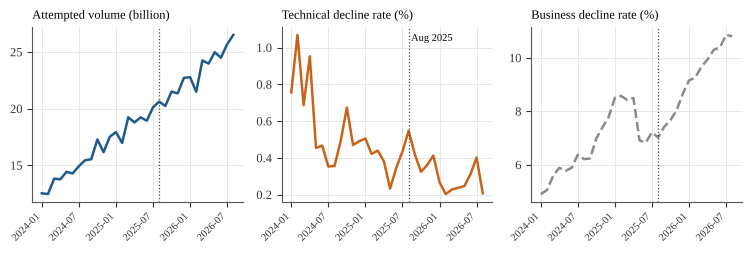

In [11]:
xt = list(range(0, len(months), 3)); xl = [months[i] for i in xt]
# Fig 1: system trend
fig, ax = plt.subplots(1, 3, figsize=(7.6, 2.6))
ax[0].plot(mon.t, mon.vol / 1000, color=BLUE, lw=1.8); ax[0].set_title("Attempted volume (billion)", fontsize=9, loc="left")
ax[1].plot(mon.t, mon.td, color=ORANGE, lw=1.8); ax[1].set_title("Technical decline rate (%)", fontsize=9, loc="left")
ax[2].plot(mon.t, mon.bd, color=GREY, lw=1.8, ls="--"); ax[2].set_title("Business decline rate (%)", fontsize=9, loc="left")
for a in ax:
    a.set_xticks(xt[::2]); a.set_xticklabels(xl[::2], rotation=45, ha="right", fontsize=7.5)
    a.axvline(midx["2025-08"], color="#444444", lw=0.9, ls=":")
ax[1].text(midx["2025-08"] + .4, mon.td.max() * .97, "Aug 2025", fontsize=7.5)
save(fig, "fig1_system_trends.png")

**Figure 5 – TD distribution and bank-group differences**

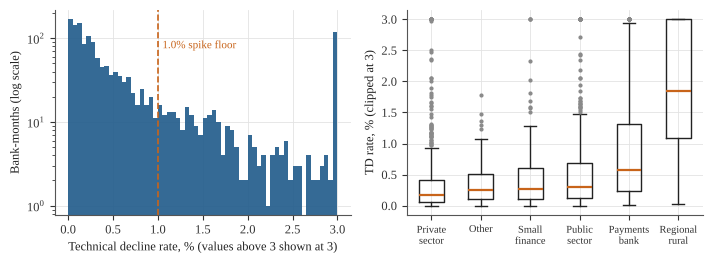

In [12]:
# Fig 2: distribution of TD
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.7))
ax[0].hist(d.td_pct.clip(upper=3), bins=60, color=BLUE, alpha=.9); ax[0].set_yscale("log")
ax[0].set_xlabel("Technical decline rate, % (values above 3 shown at 3)"); ax[0].set_ylabel("Bank-months (log scale)")
ax[0].axvline(1.0, color=ORANGE, ls="--", lw=1.2); ax[0].text(1.05, ax[0].get_ylim()[1] * .35, "1.0% spike floor", color=ORANGE, fontsize=8)
order = d.groupby("group").td_pct.median().sort_values().index.tolist()
ax[1].boxplot([d[d.group == g_].td_pct.clip(upper=3) for g_ in order], tick_labels=[o.replace(" ", "\n", 1) for o in order], showfliers=True,
              flierprops=dict(marker="o", markersize=2, markerfacecolor=GREY, markeredgecolor=GREY), medianprops=dict(color=ORANGE, lw=1.6),
              boxprops=dict(color=DARK), whiskerprops=dict(color=DARK), capprops=dict(color=DARK))
ax[1].set_ylabel("TD rate, % (clipped at 3)"); ax[1].tick_params(axis="x", labelsize=7.5)
save(fig, "fig2_td_distribution.png")

**Figure 6 – bank size vs median TD**

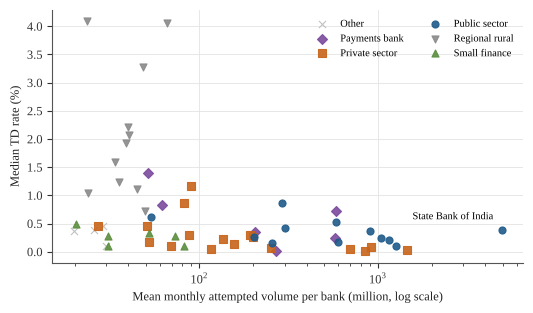

In [13]:
# Fig 3: bank heterogeneity scatter
fig, ax = plt.subplots(figsize=(5.4, 3.2))
cols = {"Public sector": BLUE, "Private sector": ORANGE, "Small finance": "#5b8e3e", "Payments bank": "#7b4a9c", "Regional rural": GREY, "Other": "#bbbbbb"}
mk = {"Public sector": "o", "Private sector": "s", "Small finance": "^", "Payments bank": "D", "Regional rural": "v", "Other": "x"}
for gname, gg in bank.groupby("group"):
    ax.scatter(gg.vol, gg.tdmed, s=26, color=cols[gname], marker=mk[gname], label=gname, alpha=.9, lw=.8)
ax.set_xscale("log"); ax.set_xlabel("Mean monthly attempted volume per bank (million, log scale)"); ax.set_ylabel("Median TD rate (%)")
r_ = bank.sort_values("vol", ascending=False).iloc[0]
ax.annotate("State Bank of India", (r_.vol, r_.tdmed), fontsize=7.5, xytext=(-6, 8), textcoords="offset points", ha="right")
ax.legend(fontsize=7.5, frameon=False, ncol=2)
save(fig, "fig3_bank_scatter.png")

**Figure 7 – calendar-month pattern**

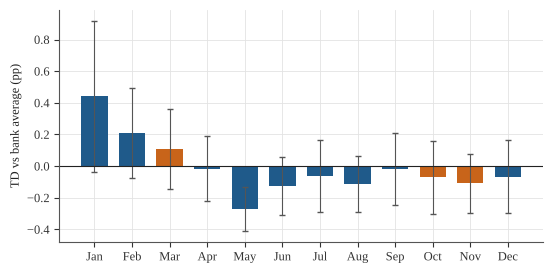

In [14]:
# Fig 4: seasonality
fig, ax = plt.subplots(figsize=(5.6, 2.8))
cc = [ORANGE if m in (3, 10, 11) else BLUE for m in season.mon]
ax.bar(season.mon, season["mean"], color=cc, width=.7, yerr=1.96 * season["sem"], error_kw=dict(ecolor="#555555", lw=.8, capsize=2))
ax.axhline(0, color=DARK, lw=.8); ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("TD vs bank average (pp)")
save(fig, "fig4_seasonality.png")

**Figure 8 – volume growth vs change in TD**

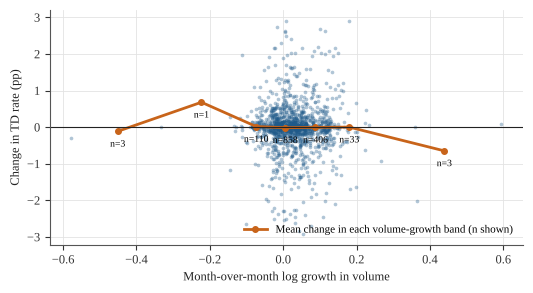

In [15]:
# Fig 5: volume growth vs TD change
fig, ax = plt.subplots(figsize=(5.4, 3.0))
gg = g[(g.dTD.abs() < 3) & (g.dlnV.abs() < 0.8)]
ax.scatter(gg.dlnV, gg.dTD, s=7, color=BLUE, alpha=.35, lw=0)
bins = pd.cut(gg.dlnV, [-0.8, -0.3, -0.15, -0.05, 0.05, 0.15, 0.3, 0.8])
bm = gg.groupby(bins, observed=True).agg(x=("dlnV", "mean"), y=("dTD", "mean"))
bm["n"] = gg.groupby(bins, observed=True).size().values
ax.plot(bm.x, bm.y, color=ORANGE, lw=2, marker="o", ms=4, label="Mean change in each volume-growth band (n shown)")
for _, r_ in bm.iterrows(): ax.annotate(f"n={int(r_.n)}", (r_.x, r_.y), xytext=(0, -11), textcoords="offset points", ha="center", fontsize=7)
ax.axhline(0, color=DARK, lw=.8); ax.set_xlabel("Month-over-month log growth in volume"); ax.set_ylabel("Change in TD rate (pp)")
ax.legend(fontsize=8, frameon=False, loc="lower right")
save(fig, "fig5_growth_vs_td.png")

**Figure 9 – spikes by month**

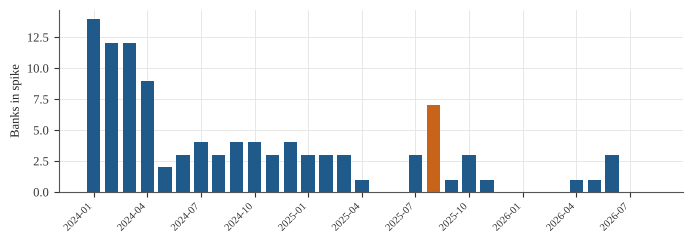

In [16]:
# Fig 6: spikes by month
fig, ax = plt.subplots(figsize=(7.0, 2.5))
ax.bar(range(len(months)), spk_month.values, color=[ORANGE if m == "2025-08" else BLUE for m in months], width=.75)
ax.set_xticks(xt); ax.set_xticklabels(xl, rotation=45, ha="right", fontsize=7.5); ax.set_ylabel("Banks in spike")
save(fig, "fig6_spikes_by_month.png")

## 5. Preliminary models for RQ1, RQ3, RQ4
**RQ1** fractional logit with bank and month effects (cluster-robust SE) — **Table 10**.

In [17]:
# ------------------------------------------------------------------ preliminary models
# ---- RQ1: fractional logit, entity + month FE, cluster-robust SE
def frac_fit(df, xcols, fe_month=True, extra=None):
    X = pd.get_dummies(df[["entity"] + (["month"] if fe_month else [])], drop_first=True, dtype=float)
    X = pd.concat([df[xcols].reset_index(drop=True), X.reset_index(drop=True)], axis=1)
    if extra is not None: X = pd.concat([X, extra.reset_index(drop=True)], axis=1)
    X = sm.add_constant(X)
    codes = pd.factorize(df.entity)[0]
    m = sm.GLM(df.p.values, X, family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": codes})
    mu = m.predict(X); wt = float((mu * (1 - mu)).mean())
    return m, wt
r1 = d.dropna(subset=["dlnV"]).copy()
r1["lagp"] = r1.groupby("entity").p.shift(1)
rq1 = {}
for name, xc, dd in [("A", ["dlnV", "newpeak"], r1), ("B", ["dlnV", "newpeak", "lagp"], r1.dropna(subset=["lagp"]))]:
    m, wt = frac_fit(dd, xc)
    rq1[name] = dict(n=int(len(dd)), clusters=int(dd.entity.nunique()),
                     **{f"{v}_coef": float(m.params[v]) for v in xc}, **{f"{v}_se": float(m.bse[v]) for v in xc}, **{f"{v}_p": float(m.pvalues[v]) for v in xc},
                     ame_dlnV_pp_per_10pct=float(m.params["dlnV"] * wt * 100 * np.log(1.1)),
                     ame_newpeak_pp=float(m.params["newpeak"] * wt * 100),
                     ci_dlnV=[float(m.conf_int().loc["dlnV", 0]), float(m.conf_int().loc["dlnV", 1])],
                     ci_newpeak=[float(m.conf_int().loc["newpeak", 0]), float(m.conf_int().loc["newpeak", 1])],
                     mean_wt=wt, odds_ratio_dlnV_10pct=float(np.exp(m.params["dlnV"] * np.log(1.1))))
res["rq1"] = rq1
rows=[]
for k in ["A","B"]:
    r=res["rq1"][k]
    for v in ["dlnV","newpeak"]:
        rows.append(dict(model=k, var=v, coef=r[v+"_coef"], se=r[v+"_se"], p=r[v+"_p"]))
display(pd.DataFrame(rows).round(3)); print({k:(round(v["ame_dlnV_pp_per_10pct"],3), round(v["ame_newpeak_pp"],3)) for k,v in res["rq1"].items()}, "<- AME (pp): 10% jump, new peak")

,model,var,coef,se,p
0,A,dlnV,0.355,0.662,0.592
1,A,newpeak,0.062,0.118,0.602
2,B,dlnV,1.165,0.854,0.172
3,B,newpeak,0.200,0.121,0.099


{'A': (0.029, 0.054), 'B': (0.093, 0.167)} <- AME (pp): 10% jump, new peak


**RQ3** — peak months (entity effects + trend + Post).

In [18]:
# ---- RQ3: peaks (entity FE + linear trend + Post + Peak + Peak x exposure)
r3 = d.copy(); r3["tt"] = r3.t / 10.0
expo = r3.groupby("entity").lnV.transform("mean"); r3["expo"] = (expo - expo.mean()) / expo.std()
r3["peak_x_expo"] = r3.peak * r3.expo
m3, wt3 = frac_fit(r3, ["peak", "peak_x_expo", "tt", "post"], fe_month=False)
res["rq3"] = dict(n=int(len(r3)), peak_bank_months=int(r3.peak.sum()),
                  peak_coef=float(m3.params["peak"]), peak_se=float(m3.bse["peak"]), peak_p=float(m3.pvalues["peak"]),
                  int_coef=float(m3.params["peak_x_expo"]), int_se=float(m3.bse["peak_x_expo"]), int_p=float(m3.pvalues["peak_x_expo"]),
                  ame_peak_pp=float(m3.params["peak"] * wt3 * 100), ci_peak=[float(x) for x in m3.conf_int().loc["peak"]],
                  raw_peak_mean=float(d[d.peak == 1].td_dm.mean()), raw_other_mean=float(d[d.peak == 0].td_dm.mean()),
                  march_mean=float(d[d.mon == 3].td_dm.mean()))
# March 2025 sensitivity (drop the Mar-2025 outage-adjacent months)
r3b = r3[~r3.month.isin(["2025-03", "2025-04"])]
m3b, wt3b = frac_fit(r3b, ["peak", "peak_x_expo", "tt", "post"], fe_month=False)
res["rq3"]["peak_coef_ex_mar25"] = float(m3b.params["peak"]); res["rq3"]["peak_se_ex_mar25"] = float(m3b.bse["peak"])
pd.Series(res['rq3'])

n                                                            1555
peak_bank_months                                              342
peak_coef                                               -0.025027
peak_se                                                  0.056176
peak_p                                                   0.655956
int_coef                                                  0.03962
int_se                                                    0.06098
int_p                                                    0.515872
ame_peak_pp                                             -0.023056
ci_peak               [-0.13512925458620187, 0.08507611543068921]
raw_peak_mean                                           -0.005054
raw_other_mean                                           0.001425
march_mean                                               0.107712
peak_coef_ex_mar25                                      -0.062941
peak_se_ex_mar25                                         0.065182
dtype: obj

**RQ4** — ICC, persistence, spike episodes, Kaplan–Meier, Cox (**Figure 11**).

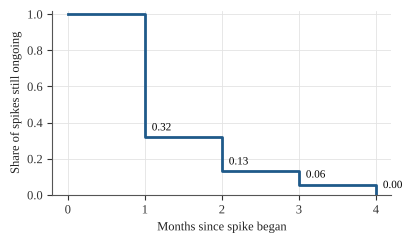

icc                   0.557177
s_between             1.590632
s_within              1.264172
rho                   0.317938
half_life             0.604894
spike_months        104.000000
banks                37.000000
episodes             69.000000
recovered            69.000000
median                1.000000
mean                  1.507246
max                   4.000000
one_month             0.681159
start_peak_share      0.246377


,t,at_risk,events,S
0,1,69,47,0.318841
1,2,22,13,0.130435
2,3,9,5,0.057971
3,4,4,4,0.000000


{'names': ['lnV_z', 'start_peak', 'public'], 'hr': [1.0664395780145601, 1.267293951529732, 0.6318690562746875], 'p': [0.6823003768270341, 0.41097050932983226, 0.18767187690560916], 'ci': [[0.7837362114510867, 1.4511175532519744], [0.7204999548596125, 2.2290549065985354], [0.319177077075934, 1.2508996821926481]], 'n': 69, 'events': 69}


In [19]:
# ---- RQ4: ICC, AR(1), episodes, KM, Cox
mm = smf.mixedlm("logit ~ 1", d, groups=d["entity"]).fit()
s_b = float(mm.cov_re.iloc[0, 0]); s_w = float(mm.scale)
d["dm"] = d.logit - d.groupby("entity").logit.transform("mean"); d["lagdm"] = d.groupby("entity").dm.shift(1)
a_ = d.dropna(subset=["lagdm"]); rho = float((a_.dm * a_.lagdm).sum() / (a_.lagdm ** 2).sum())
episodes = []
for e, gg_ in d.groupby("entity"):
    run, start = 0, None
    for _, r in gg_.iterrows():
        if r.spike:
            if run == 0: start = r.month
            run += 1
        elif run:
            episodes.append((e, run, 1, start)); run = 0
    if run: episodes.append((e, run, 0, start))
ep = pd.DataFrame(episodes, columns=["entity", "dur", "event", "start"])
ep["start_peak"] = ep.start.str[5:].astype(int).isin([3, 10, 11]).astype(int)
ep["group"] = ep.entity.map(grp); ep["public"] = (ep.group == "Public sector").astype(int)
bm_ = d.groupby("entity").lnV.mean(); ep["lnV"] = ep.entity.map(bm_); ep["lnV_z"] = (ep.lnV - bm_.mean()) / bm_.std()
km, S = [], 1.0
for tt_ in range(1, int(ep.dur.max()) + 1):
    n_ = int((ep.dur >= tt_).sum()); d_ = int(((ep.dur == tt_) & (ep.event == 1)).sum())
    S *= (1 - d_ / n_) if n_ else 1; km.append(dict(t=tt_, at_risk=n_, events=d_, S=S))
res["km"] = km
try:
    cox = PHReg(ep.dur.values.astype(float), ep[["lnV_z", "start_peak", "public"]].values, status=ep.event.values, ties="efron").fit()
    res["cox"] = dict(names=["lnV_z", "start_peak", "public"], hr=[float(x) for x in np.exp(cox.params)], p=[float(x) for x in cox.pvalues],
                      ci=[[float(a), float(b)] for a, b in np.exp(cox.conf_int())], n=int(len(ep)), events=int(ep.event.sum()))
except Exception as ex:
    res["cox"] = dict(error=str(ex))
res["rq4"] = dict(icc=s_b / (s_b + s_w), s_between=s_b, s_within=s_w, rho=rho, half_life=float(np.log(.5) / np.log(rho)),
                  spike_months=int(d.spike.sum()), banks=int(d[d.spike == 1].entity.nunique()), episodes=int(len(ep)),
                  recovered=int(ep.event.sum()), median=float(ep.dur.median()), mean=float(ep.dur.mean()), max=int(ep.dur.max()),
                  one_month=float((ep.dur == 1).mean()), start_peak_share=float(ep.start_peak.mean()),
                  by_group_mean=ep.groupby("group").dur.mean().round(2).to_dict(), ep_by_group=ep.groupby("group").size().to_dict())
fig, ax = plt.subplots(figsize=(4.2, 2.5))
xs = [0] + [k["t"] for k in km]; ys = [1.0] + [k["S"] for k in km]
ax.step(xs, ys, where="post", color=BLUE, lw=2); ax.set_ylim(0, 1.02); ax.set_xticks(xs)
ax.set_xlabel("Months since spike began"); ax.set_ylabel("Share of spikes still ongoing")
for x_, y_ in zip(xs[1:], ys[1:]): ax.annotate(f"{y_:.2f}", (x_, y_), xytext=(5, 5), textcoords="offset points", fontsize=8)
save(fig, "fig7_km.png")
print(pd.Series({k:v for k,v in res['rq4'].items() if not isinstance(v,dict)}).to_string()); display(pd.DataFrame(res['km'])); print(res['cox'])

## 6. RQ2 — timing of the API controls (Table 11, Figure 10)
Runs the repository's `code/rq2_robustness.py` (five ITS specifications, placebo breaks, BD placebo). It is executed in a separate process so its plotting backend does not affect this notebook.

04003322437907461,
   "hi": 0.28537679716337105,
   "n": 32
  },
  "aug2025": {
   "b": 0.1727615016409642,
   "se": 0.06252510311471006,
   "lo": 0.04488330737335541,
   "hi": 0.300639695908573,
   "n": 32
  }
 },
 "means": {
  "pre": 0.5251210471392407,
  "post": 0.32030208841243407,
  "pre12": 0.43676233944822546,
  "n_pre": 19,
  "n_post": 13
 },
 "entity": {
  "Mapped (as planned)": {
   "no_trend": {
    "coef": -0.4701328970701528,
    "se": 0.08573653131168062,
    "OR": 0.6249192128314425,
    "n": 1555,
    "clusters": 56
   },
   "trend": {
    "coef": 0.5770672750780442,
    "se": 0.3339663945722697,
    "OR": 1.7808081445766994,
    "n": 1555,
    "clusters": 56
   }
  },
  "Not mapped (two entities)": {
   "no_trend": {
    "coef": -0.48383532688994274,
    "se": 0.0841703016362585,
    "OR": 0.616414700480831,
    "n": 1555,
    "clusters": 57
   },
   "trend": {
    "coef": 0.5830481692468893,
    "se": 0.32899845494932467,
    "OR": 1.7914908839468116,
    "n": 1555,
 

,estimate,ci_lo,ci_hi,rank_of_Aug_(of_21)
A. Step only (no trend),-0.205,-0.361,-0.049,20.0
B. Linear trend + step (planned),0.173,0.045,0.301,3.0
"C. 12 months before vs after, step",-0.116,-0.222,-0.011,NaN
"D. Log TD, step only",-0.472,-0.797,-0.148,19.0
"E. Log TD, linear trend + step",0.264,0.028,0.500,3.0


Placebo breaks, spec B: {'2024-07': -0.189, '2025-06': 0.163, '2025-07': 0.194, '2025-08': 0.173}


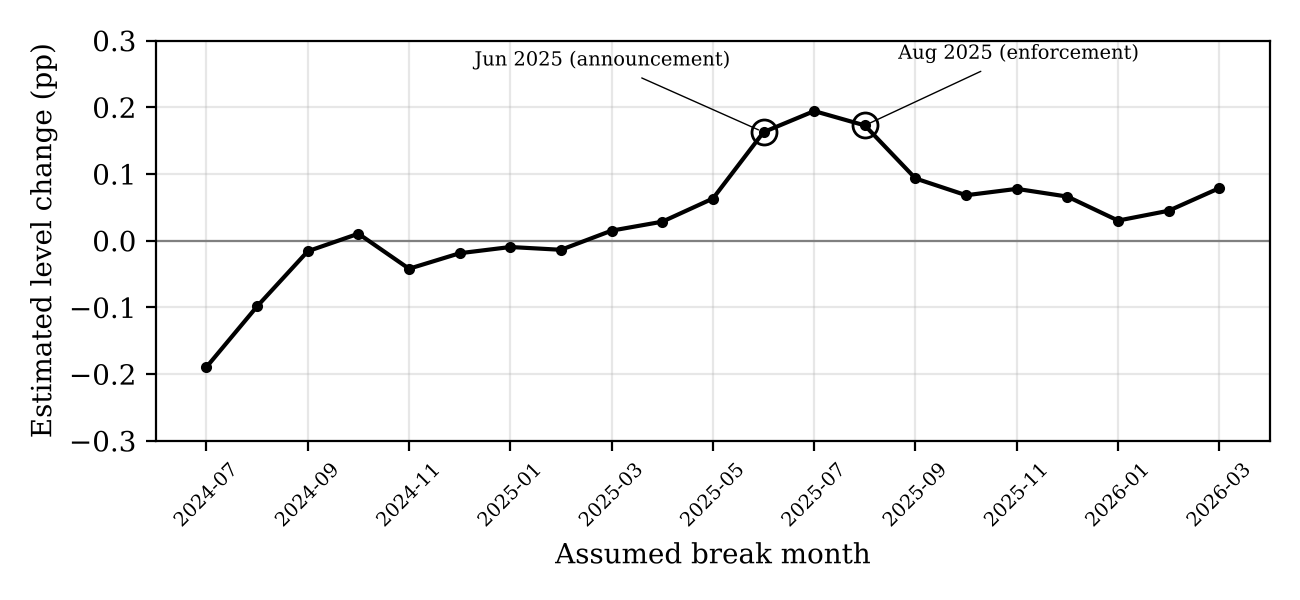

In [20]:
src = open("code/rq2_robustness.py").read()
for old in ['"../upi_remitter_top50_panel.csv"', "'../upi_remitter_top50_panel.csv'"]:
    src = src.replace(old, '"../data/processed/upi_remitter_top50_panel.csv"')
open("code/_rq2_colab.py", "w").write(src)
r = subprocess.run(["python", "_rq2_colab.py"], cwd="code", capture_output=True, text=True)
print(r.stdout[-1500:] if r.returncode == 0 else r.stderr[-2500:])
import json
from IPython.display import Image, display
Q = json.load(open("code/rq2_results.json"))
tab = pd.DataFrame({k: {"estimate": v["b"], "ci_lo": v["lo"], "ci_hi": v["hi"], "rank_of_Aug_(of_21)": v.get("rank_abs")} for k, v in Q["specs"].items()}).T
print("Table 11"); display(tab.round(3))
print("Placebo breaks, spec B:", {k: round(v, 3) for k, v in Q["placebo_B"].items() if k in ("2024-07", "2025-06", "2025-07", "2025-08")})
display(Image("code/fig2.png"))

## 7. Prediction benchmark (Tables 12–13, Figure 12)
Rolling-origin validation: each target month Jan–Aug 2026 is predicted from earlier months only.
Baselines: naive (last month) and bank history mean; models: fractional logit and XGBoost.

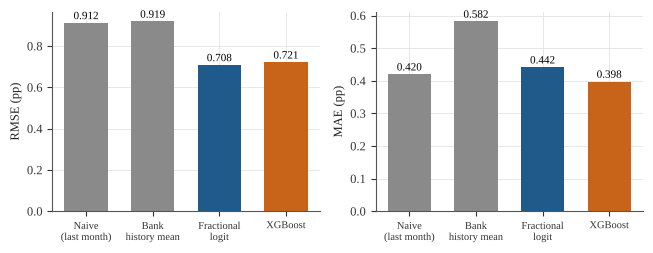

In [21]:
# ------------------------------------------------------------------ prediction benchmark
d = d.sort_values(["entity", "t"]).reset_index(drop=True)
d["td_l1"] = d.groupby("entity").td_pct.shift(1); d["td_l2"] = d.groupby("entity").td_pct.shift(2)
d["bd_l0"] = d.bd_pct
d["hist_mean"] = d.groupby("entity").td_pct.transform(lambda x: x.expanding().mean())
d["next_td"] = d.groupby("entity").td_pct.shift(-1); d["next_t"] = d.groupby("entity").t.shift(-1)
d["next_spike"] = d.groupby("entity").spike.shift(-1)
d["next_month"] = d.groupby("entity").month.shift(-1)
M = d[(d.next_t == d.t + 1) & d.dlnV.notna() & d.td_l1.notna()].copy()
M["nm"] = M.next_month.str[5:].astype(int)
M["sin_m"] = np.sin(2 * np.pi * M.nm / 12); M["cos_m"] = np.cos(2 * np.pi * M.nm / 12); M["peak_next"] = M.nm.isin([3, 10, 11]).astype(int)
for gname in ["Public sector", "Private sector", "Small finance", "Payments bank", "Regional rural"]:
    M["g_" + gname.split()[0]] = (M.group == gname).astype(int)
FEATS = ["td_pct", "td_l1", "bd_l0", "lnV", "dlnV", "newpeak", "hist_mean", "sin_m", "cos_m", "peak_next"] + [c for c in M.columns if c.startswith("g_")]
res["features"] = FEATS
test_months = [m for m in months if m >= "2026-01"]
rows = []
def metrics(y, yh): return float(np.sqrt(np.mean((y - yh) ** 2))), float(np.mean(np.abs(y - yh)))
preds = {k: [] for k in ["naive", "histmean", "glm", "xgb", "xgbc"]}
idx_all = []
for m in test_months:
    tr = M[M.next_month < m]; te = M[M.next_month == m]
    if te.empty: continue
    idx_all += list(te.index)
    preds["naive"].append(te.td_pct.values)
    preds["histmean"].append(te.hist_mean.values)
    # fractional logit with group dummies
    Xtr = sm.add_constant(tr[FEATS].astype(float)); Xte = sm.add_constant(te[FEATS].astype(float), has_constant="add")
    g1 = sm.GLM((tr.next_td / 100).clip(0, 0.5).values, Xtr, family=sm.families.Binomial()).fit()
    preds["glm"].append(g1.predict(Xte).values * 100)
    xr = xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=2, verbosity=0)
    xr.fit(tr[FEATS], tr.next_td.clip(upper=10)); preds["xgb"].append(xr.predict(te[FEATS]))
    pos = tr.next_spike.sum(); neg = len(tr) - pos
    xc = xgb.XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=SEED,
                           scale_pos_weight=neg / max(pos, 1), n_jobs=2, verbosity=0)
    xc.fit(tr[FEATS], tr.next_spike); preds["xgbc"].append(xc.predict_proba(te[FEATS])[:, 1])
T = M.loc[idx_all].copy()
for k in preds: T["p_" + k] = np.concatenate(preds[k])
y = T.next_td.values; ys = T.next_spike.values.astype(int)
perf = {}
for k in ["naive", "histmean", "glm", "xgb"]:
    r_, m_ = metrics(y, T["p_" + k].values)
    # robust version: RMSE excluding the single largest-error bank-month
    perf[k] = dict(rmse=r_, mae=m_)
    score = T["p_" + k].values
    perf[k]["pr_auc"] = float(average_precision_score(ys, score)) if ys.sum() else None
    pred_sp = (score >= 1.0).astype(int) if k != "naive" else T.spike.values.astype(int)
    tp = int(((pred_sp == 1) & (ys == 1)).sum())
    perf[k].update(precision=tp / max(int(pred_sp.sum()), 1), recall=tp / max(int(ys.sum()), 1), flagged=int(pred_sp.sum()))
sc = T.p_xgbc.values; pred_sp = (sc >= 0.5).astype(int); tp = int(((pred_sp == 1) & (ys == 1)).sum())
perf["xgb_clf"] = dict(pr_auc=float(average_precision_score(ys, sc)), precision=tp / max(int(pred_sp.sum()), 1), recall=tp / max(int(ys.sum()), 1), flagged=int(pred_sp.sum()))
perf["n_test"] = int(len(T)); perf["test_spikes"] = int(ys.sum()); perf["base_rate"] = float(ys.mean())
# error sensitivity: share of squared error from top-3 errors in naive and xgb
for k in ["naive", "xgb"]:
    e2 = (y - T["p_" + k].values) ** 2; perf[k]["top3_sq_share"] = float(np.sort(e2)[-3:].sum() / e2.sum())
    keep = np.argsort(e2)[:-3]; perf[k]["rmse_ex_top3"] = float(np.sqrt(e2[keep].mean()))
# feature importance (last fit, regression)
imp = pd.Series(xr.feature_importances_, index=FEATS).sort_values(ascending=False)
perf["importance"] = imp.round(3).to_dict()
res["perf"] = perf
res["train_spikes_end"] = int(M[M.next_month < "2026-01"].next_spike.sum()); res["train_n_end"] = int((M.next_month < "2026-01").sum())

# bar chart of RMSE / MAE
fig, ax = plt.subplots(1, 2, figsize=(6.6, 2.6))
names = ["Naive\n(last month)", "Bank\nhistory mean", "Fractional\nlogit", "XGBoost"]; ks = ["naive", "histmean", "glm", "xgb"]
cb = [GREY, GREY, BLUE, ORANGE]
for a, met, lab in [(ax[0], "rmse", "RMSE (pp)"), (ax[1], "mae", "MAE (pp)")]:
    vals = [perf[k][met] for k in ks]; a.bar(range(4), vals, color=cb, width=.65)
    a.set_xticks(range(4)); a.set_xticklabels(names, fontsize=7.5); a.set_ylabel(lab)
    for i, v in enumerate(vals): a.text(i, v + max(vals) * .02, f"{v:.3f}", ha="center", fontsize=8)
save(fig, "fig8_model_compare.png")

In [22]:
t12 = pd.DataFrame({k: {"RMSE": perf[k]["rmse"], "MAE": perf[k]["mae"]} for k in ["naive","histmean","glm","xgb"]}).T
print("Table 12"); display(t12.round(3))
t13 = pd.DataFrame({k: {kk: perf[k][kk] for kk in ["flagged","precision","recall","pr_auc"]} for k in ["naive","glm","xgb","xgb_clf"]}).T
print("Table 13"); display(t13.round(3))
print("n_test", perf["n_test"], "test spikes", perf["test_spikes"], "base rate", round(perf["base_rate"], 4))
print("Feature importance:"); display(pd.Series(perf["importance"]).head(8))

Table 12


,RMSE,MAE
naive,0.912,0.420
histmean,0.919,0.582
glm,0.708,0.442
xgb,0.721,0.398


Table 13


,flagged,precision,recall,pr_auc
naive,5.0,0.400,0.4,0.050
glm,76.0,0.026,0.4,0.028
xgb,74.0,0.027,0.4,0.039
xgb_clf,17.0,0.000,0.0,0.041


n_test 374 test spikes 5 base rate 0.0134
Feature importance:


g_Regional    0.279
td_pct        0.139
hist_mean     0.086
td_l1         0.071
lnV           0.066
newpeak       0.050
bd_l0         0.048
cos_m         0.047
dtype: float64

## 8. Save results

In [23]:
res["rq2"] = Q
json.dump(res, open("code/interim_results.json", "w"), indent=1, default=lambda x: float(x) if hasattr(x, "__float__") else str(x))
print("Saved code/interim_results.json;", len(os.listdir("outputs")), "figures in outputs/")

Saved code/interim_results.json; 8 figures in outputs/


### Reproducibility notes
- Random seed 42; XGBoost: 300 trees, depth 3, learning rate 0.05, subsample 0.8.
- Spike = robust z-score of TD > 3 (bank median/MAD) and TD ≥ 1.0%.
- Figures 1–3 in the report are screenshots; Table 1 (literature) and Table 2 (data dictionary) are not computed.